In [114]:
import numpy as np 
import matplotlib.pyplot as plt

prs = 500
x1, y1 =  1, 1
a = 2
x2, y2 = 5, 4
b = 1
xmin, xmax = 0, 6.5
ymin, ymax = 0, 5.5

def in_sq(P):
    in1 = (P[:, 0] >= x1) & (P[:, 0] <= x1 + a) & (P[:, 1] >= y1) & (P[:, 1] <= y1 + a)
    in2 = (P[:, 0] >= x2) & (P[:, 0] <= x2 + b) & (P[:, 1] >= y2) & (P[:, 1] <= y2 + b)
    return in1 | in2

def ran_out(n):
    points = []
    i = 0
    while i < n:
        z1 = np.random.uniform(low=xmin, high=xmax, size=n)
        z2 = np.random.uniform(low=ymin, high=ymax, size=n)
        P = np.column_stack((z1, z2))
        P = P[~in_sq(P)] #выберем все все квадратиков 
        points.append(P)
        i += len(P)
    return np.vstack(points)[:n] #np.vstack(points) склеивает все порции из списка друг под другом в одну большую таблицу. [:n] — это срез, «взять строки с начала до n». Последняя порция могла дать лишние точки, и мы обрезаем результат ровно до n


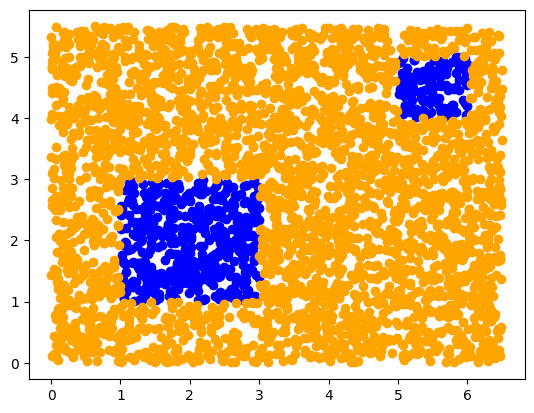

In [115]:
X1 = np.random.uniform(low=x1 , high=x1 + a, size= prs)
Y1 = np.random.uniform(low=y1, high=y1 + a, size=prs)
X2 = np.random.uniform(low=x2, high=x2 + b, size= prs // 4)
Y2 = np.random.uniform(low=y2, high=y2 + b, size=prs // 4)

X = np.concatenate([X1, X2])
Y = np.concatenate([Y1, Y2])


t1 = np.column_stack((X, Y))
t2 = ran_out(int(prs * ((ymax - ymin) * (xmax - xmin) - b**2 - a**2) / (b**2 + a**2)))

plt.scatter(X, Y, color= 'blue', label='class 1')
plt.scatter(t2[:, 0], t2[:, 1], color='orange', label='class 2')
plt.show()

In [143]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

lab1 = np.zeros(len(t1))
lab2 = np.ones(len(t2))

Xt = np.vstack([t1, t2])
Yt = np.concatenate([lab1, lab2])

x_tr, xt, y_tr, yt = train_test_split(Xt, Yt, test_size=0.2, random_state=9) #парметр random_state определяет способ выбора 20 и 80 процентов из выборки. Генератор случайных числев будет стартовать с всегда с 9
scaler = StandardScaler()
x_tr_sc = scaler.fit_transform(x_tr)
xt_sc = scaler.transform(xt)

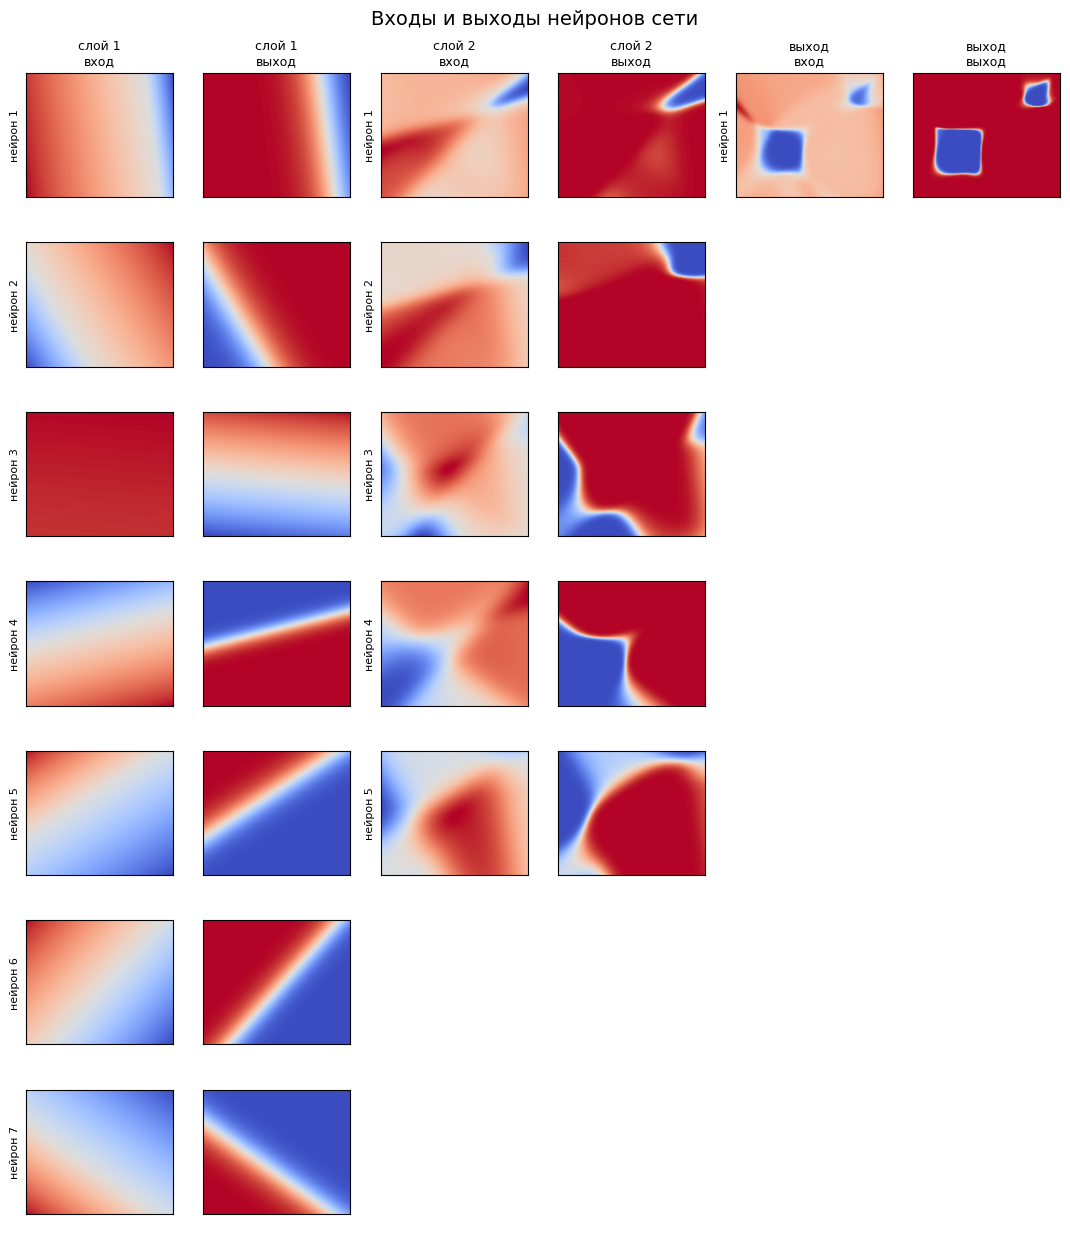

Эпох прошло: 181  итоговая ошибка: 0.022401280343711517


In [144]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(7, 5), 
    activation='tanh', #tanh, relu
    solver='adam', #стохастический градиентный спуск, который сам себе параметры подбирает, умнее адама тк квазиньютоновский метод использует не только наклон, но и приближённую кривизну поверхности ошибки, поэтому выбирает шаги «умнее».
    learning_rate_init=0.018,
    max_iter=2000, #максимум эпох (проходов по всей обучающей выборке)
    random_state=9
)

mlp.fit(x_tr_sc, y_tr)



from matplotlib.colors import TwoSlopeNorm

def layer_outputs(mlp, X):
    """Для каждого слоя возвращает (z, a): z — вход нейронов, a — выход."""
    acts = {
        'relu':     lambda z: np.maximum(z, 0),
        'tanh':     np.tanh,
        'logistic': lambda z: 1 / (1 + np.exp(-z)),
        'identity': lambda z: z,
    }
    a = X
    result = []
    n_layers = len(mlp.coefs_)
    for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
        z = a @ W + b
        f = acts[mlp.activation] if i < n_layers - 1 else acts[mlp.out_activation_]
        a = f(z)
        result.append((z, a))
    return result


def plot_neurons(mlp, scaler=None, res=150):
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, res), np.linspace(ymin, ymax, res))
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    if scaler is not None:              # нормируем, только если сеть училась на нормированных данных
        grid = scaler.transform(grid)
    outputs = layer_outputs(mlp, grid)

    n_cols = 2 * len(outputs)
    n_rows = max(z.shape[1] for z, _ in outputs)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.8 * n_cols, 1.8 * n_rows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis('off')

    extent = (xmin, xmax, ymin, ymax)
    for L, (z, a) in enumerate(outputs):
        name = f"слой {L+1}" if L < len(outputs) - 1 else "выход"
        for j in range(z.shape[1]):
            zj = z[:, j].reshape(xx.shape)
            aj = a[:, j].reshape(xx.shape)

            # вход нейрона (белый = 0, красный > 0, синий < 0)
            ax = axes[j, 2 * L]
            norm = TwoSlopeNorm(vcenter=0, vmin=min(zj.min(), -1e-6), vmax=max(zj.max(), 1e-6))
            ax.imshow(zj, origin='lower', extent=extent, cmap='coolwarm', norm=norm)

            # выход нейрона после активации
            ax2 = axes[j, 2 * L + 1]
            ax2.imshow(aj, origin='lower', extent=extent, cmap='coolwarm')

            for ax_ in (ax, ax2):
                ax_.axis('on'); ax_.set_xticks([]); ax_.set_yticks([])
            ax.set_ylabel(f"нейрон {j+1}", fontsize=8)

        axes[0, 2 * L].set_title(f"{name}\nвход", fontsize=9)
        axes[0, 2 * L + 1].set_title(f"{name}\nвыход", fontsize=9)

    fig.suptitle("Входы и выходы нейронов сети", fontsize=14)
    plt.tight_layout()
    plt.show()


plot_neurons(mlp, scaler)
print("Эпох прошло:", mlp.n_iter_, " итоговая ошибка:", mlp.loss_)

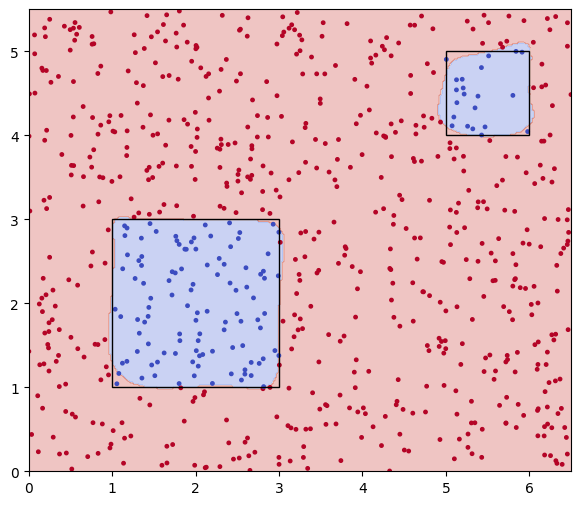

0.9918831168831169 0.9983660130718954


In [145]:
from sklearn.metrics import  precision_score, recall_score

y_pr = mlp.predict(xt_sc)

prec = precision_score(yt, y_pr)
rec = recall_score(yt, y_pr)

xx, yy = np.meshgrid(np.linspace(xmin, xmax, 300), np.linspace(ymin, ymax, 300))
grid = np.column_stack((xx.ravel(), yy.ravel()))
zz = mlp.predict(scaler.transform(grid)).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
plt.scatter(xt[:, 0], xt[:, 1], c=yt, cmap='coolwarm', s=6)
plt.gca().add_patch(plt.Rectangle((x1, y1), a, a, fill=False))
plt.gca().add_patch(plt.Rectangle((x2, y2), b, b, fill=False))
plt.show()
print(prec, rec)

In [146]:
def weights_tables(mlp):
    n_layers = len(mlp.coefs_)
    for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
        if i == 0:
            in_names = ['x', 'y']
        else:
            in_names = [f'Н{i}.{k+1}' for k in range(W.shape[0])]
        layer_name = f'слой {i+1}' if i < n_layers - 1 else 'выход'
        out_names = [f'Н{i+1}.{k+1}' if i < n_layers - 1 else 'выход' for k in range(W.shape[1])]

        df = pd.DataFrame(W.T, index=out_names, columns=in_names)
        df['смещение b'] = b

        print(f"\n=== {layer_name}: {W.shape[0]} входов → {W.shape[1]} нейронов ===")
        display(df.round(3))

weights_tables(mlp)


=== слой 1: 2 входов → 7 нейронов ===


,x,y,смещение b
Н1.1,-1.818,-0.212,2.309
Н1.2,1.753,0.929,1.995
Н1.3,0.006,0.057,2.069
Н1.4,1.237,-4.348,1.784
Н1.5,-1.608,2.174,-1.331
Н1.6,-2.534,1.974,0.501
Н1.7,-1.590,-1.962,-1.204



=== слой 2: 7 входов → 5 нейронов ===


,Н1.1,Н1.2,Н1.3,Н1.4,Н1.5,Н1.6,Н1.7,смещение b
Н2.1,-1.592,0.771,1.740,3.314,1.177,3.188,0.538,1.577
Н2.2,4.354,-0.245,1.102,4.916,-1.899,2.564,-0.436,-0.009
Н2.3,2.041,4.529,-1.290,0.758,-1.622,3.464,-1.328,-1.441
Н2.4,0.420,1.227,0.994,-1.746,2.272,-4.627,-3.920,1.007
Н2.5,2.547,3.212,-1.497,0.302,-3.078,0.423,-0.073,-1.673



=== выход: 5 входов → 1 нейронов ===


,Н2.1,Н2.2,Н2.3,Н2.4,Н2.5,смещение b
выход,3.565,4.772,-7.713,8.641,-3.179,1.763


Нейронов в предпоследнем слое: 5
Исходная сеть: precision = 0.992, recall = 0.998

Сводка по опытам:


precision                      recall                     
              mean    std    min    max   mean    std    min    max
обнулено                                                           
0%           0.992    NaN  0.992  0.992  0.998    NaN  0.998  0.998
25%          0.953  0.038  0.901  0.995  0.856  0.193  0.567  0.995
50%          0.915  0.058  0.827  0.987  0.750  0.287  0.288  1.000

C:\Users\kutlu\AppData\Local\Temp\ipykernel_17336\2174628057.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[i].boxplot(data, labels=['0%', '25%', '50%'])
C:\Users\kutlu\AppData\Local\Temp\ipykernel_17336\2174628057.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[i].boxplot(data, labels=['0%', '25%', '50%'])


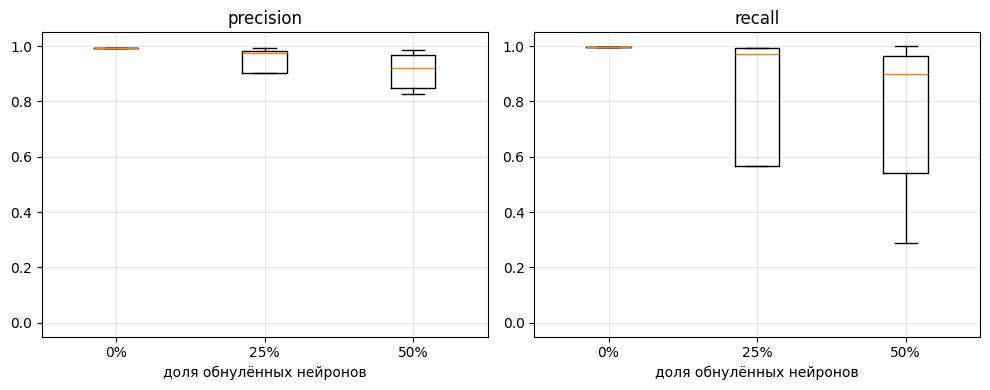

In [147]:
import copy
import pandas as pd

pos = 0

def evaluate (mod, x, y):
    pred = mod.predict(x)
    prc = precision_score(y, pred)
    recall = recall_score(y, pred)
    return prc, recall

def mod_change(mod, neir):
    m = copy.deepcopy(mod)
    m.coefs_[-1][neir, :] = 0
    return m

n = mlp.coefs_[-1].shape[0] #.shape[0] — первый элемент кортежа, то есть число строк.
p0, r0 = evaluate(mlp, xt_sc, yt)

print(f"Нейронов в предпоследнем слое: {n}")
print(f"Исходная сеть: precision = {p0:.3f}, recall = {r0:.3f}")


# 2. Обнуляем 25% и 50% нейронов, много раз случайно
rng = np.random.default_rng(9) #генератор случ чисел 
n_trials = 30  # сколько опытов проведем

rows = [{'обнулено': '0%', 'нейронов': 0, 'precision': p0, 'recall': r0, 'опыт': 0}]
for frac in [0.25, 0.5]:
    k = max(1, round(frac * n))       # сколько нейронов выключаем
    for t in range(n_trials):
        off = rng.choice(n, size=k, replace=False) #rng.choice(n, ...) выбирает случайные числа из 0, 1, …, n−1, то есть номера нейронов. size=k — сколько номеров выбрать. replace=False — без повторений:
        p, r = evaluate(mod_change(mlp, off), xt_sc, yt)
        rows.append({'обнулено': f'{int(frac*100)}%', 'нейронов': k,
                     'precision': p, 'recall': r, 'опыт': t + 1,
                     'выключены': sorted(off.tolist())})

res = pd.DataFrame(rows)

summary = res.groupby('обнулено')[['precision', 'recall']].agg(['mean', 'std', 'min', 'max'])
print("\nСводка по опытам:")
display(summary.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['precision', 'recall']):
    data = [res[res['обнулено'] == g][metric] for g in ['0%', '25%', '50%']]
    ax[i].boxplot(data, labels=['0%', '25%', '50%'])
    ax[i].set_title(metric); ax[i].set_xlabel('доля обнулённых нейронов')
    ax[i].set_ylim(-0.05, 1.05); ax[i].grid(alpha=0.3)
plt.tight_layout(); plt.show()

#верх ящика: 75% опытов дали результат НИЖЕ этого; низ ящика: 25% опытов дали результат НИЖЕ этого

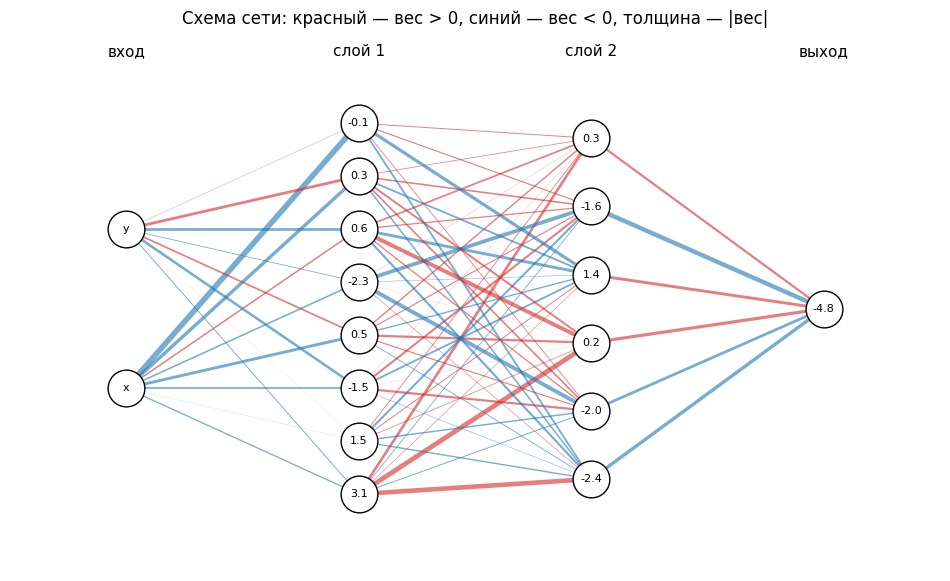

In [137]:
def draw_network(mlp):
    sizes = [mlp.coefs_[0].shape[0]] + [W.shape[1] for W in mlp.coefs_]
    names = ['вход'] + [f'слой {i+1}' for i in range(len(sizes) - 2)] + ['выход']

    # координаты кружков
    pos = [[(L, y) for y in np.linspace(0, 1, n + 2)[1:-1]] for L, n in enumerate(sizes)]
    wmax = max(np.abs(W).max() for W in mlp.coefs_)

    fig, ax = plt.subplots(figsize=(3 * len(sizes), 0.5 * max(sizes) + 3))

    # связи
    for L, W in enumerate(mlp.coefs_):
        for i in range(W.shape[0]):
            for j in range(W.shape[1]):
                w = W[i, j]
                (xa, ya), (xb, yb) = pos[L][i], pos[L + 1][j]
                ax.plot([xa, xb], [ya, yb],
                        color='tab:red' if w > 0 else 'tab:blue',
                        lw=4 * abs(w) / wmax, alpha=0.6, zorder=1)

    # нейроны
    for L, layer in enumerate(pos):
        for k, (x, y) in enumerate(layer):
            ax.scatter(x, y, s=700, c='white', edgecolors='black', zorder=2)
            text = ['x', 'y'][k] if L == 0 else f"{mlp.intercepts_[L-1][k]:.1f}"
            ax.text(x, y, text, ha='center', va='center', fontsize=8, zorder=3)
        ax.text(L, 1.03, names[L], ha='center', fontsize=11)

    ax.set_xlim(-0.5, len(sizes) - 0.5); ax.set_ylim(-0.05, 1.08)
    ax.axis('off')
    plt.title("Схема сети: красный — вес > 0, синий — вес < 0, толщина — |вес|")
    plt.show()

draw_network(mlp)